# 01 — Understanding SKAB before modelling
We first identify **what the source files contain**, then explain our choices about how to use them.
The analysis examines data quality, sensor behaviour and annotation quality. No detector, alarm
threshold or claim of failure-prediction performance is produced.

Read each output with its stated population: all opened recordings, the beginning of each recording,
or one named example. A recording is an experiment on the same testbed, not a different industrial asset.

Source: [SKAB at the pinned version](https://github.com/waico/SKAB/tree/b2c0d46c2971dcbfe71e26087b6d231998bb91c2).
The [experiment descriptions](https://github.com/waico/SKAB/blob/b2c0d46c2971dcbfe71e26087b6d231998bb91c2/data/README.md)
describe intended interventions. Our interpretations remain separate from that documentation.

In [1]:
from pathlib import Path
from dataclasses import asdict
import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ts_anomaly.skab import FAMILIES, METRICS, load_development, initial_normal
from ts_anomaly.assessment import (
    sampling_report, duplicate_report, bin_coverage, signal_profile,
    state_runs, aggregate_gauges, segment_acf, relationship_report,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "configs/skab.json").exists(), "Open the repository or its notebooks folder."
settings = json.loads((ROOT / "configs/skab.json").read_text())
OUTPUT = ROOT / "outputs/skab_assessment"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", None)
names = list(METRICS)
units = {name: definition.unit for name, definition in METRICS.items()}
manifest = pd.DataFrame(settings["files"])
manifest["family"] = manifest.recording_id.str.split("/").str[0]

# Natural filename order: other/2 precedes other/10. This is not time order.
manifest["file_number"] = pd.to_numeric(manifest.recording_id.str.split("/").str[-1], errors="coerce")
manifest = manifest.sort_values(["family", "file_number"], na_position="first").reset_index(drop=True)
print("Pinned SKAB source version:", settings["source_commit"])

Pinned SKAB source version: b2c0d46c2971dcbfe71e26087b6d231998bb91c2


## 1. What did SKAB originally provide?
An electric motor drives a pump that circulates water. A **valve is like a tap**:
restricting its opening changes the passage available to water.

```text
Water → inlet valve (valve1) → pump → outlet valve (valve2) → return
                               ↑
                         electric motor
```

This is a conceptual flow, not an exact sensor-location drawing. The two valve names identify
experiment families, not measured sensor channels. Other experiments involve fluid changes,
motor imbalance, cavitation (vapour bubbles forming and collapsing) or warmer water.

**One CSV file = one recorded run. One row = one recorded time. Eight columns = eight sensor measurements.**
The source has 34 labelled experiment recordings and one separate anomaly-free recording.
“Labelled” means annotations were supplied alongside measurements; it does not mean 34 machines
or 34 unplanned breakdowns.

The inventory below uses filenames from our pinned source manifest. It does not inspect every file's
sensor values. The original source has no folders called development or reserved test.

In [2]:
inventory_rows = []
for family, group in manifest.groupby("family", sort=False):
    inventory_rows.append({
        "source_folder": family,
        "recording_files": len(group),
        "filenames": ", ".join(Path(path).name for path in group.path),
        "source_description": FAMILIES[family],
    })
source_inventory = pd.DataFrame(inventory_rows).set_index("source_folder")
display(source_inventory)
print(f"Original source inventory: {source_inventory.recording_files.sum()} recordings.")

,recording_files,filenames,source_description
source_folder,,,
anomaly-free,1,anomaly-free.csv,Separate recording described as normal operation; no point annotations.
other,14,"1.csv, 2.csv, 3.csv, 4.csv, 5.csv, 6.csv, 7.csv, 8.csv, 9.csv, 10.csv, 11.csv, 12.csv, 13.csv, 14.csv","Other interventions: fluid changes, rotor imbalance, cavitation or warmer water."
valve1,16,"0.csv, 1.csv, 2.csv, 3.csv, 4.csv, 5.csv, 6.csv, 7.csv, 8.csv, 9.csv, 10.csv, 11.csv, 12.csv, 13.csv, 14.csv, 15.csv",Experiments restricting water entering the pump (inlet valve).
valve2,4,"0.csv, 1.csv, 2.csv, 3.csv",Experiments restricting water leaving the pump (outlet valve).


Original source inventory: 35 recordings.


### Measurements and annotations have different jobs
The dictionary describes **all eight numerical measurement channels**. It is a description of their
meaning, not evidence that their values are valid or normally distributed.

Here, **gauge** means a measured level or magnitude, rather than a cumulative counter or on/off command.
RMS summarises amplitude: the original rapid vibration waveform and its frequencies cannot be recovered.
The unit g is acceleration relative to gravity, not grams. A and V denote amperes and volts;
bar is a pressure unit, and L/min is litres per minute.

The motor body and the water have separate temperature measurements. Pressure describes pressure at a
location; flow describes volume moving per unit time. Their relationship depends on operating conditions.
No documented digital operating-command measurements are supplied.

In [3]:
dictionary = pd.DataFrame({name: asdict(definition) for name, definition in METRICS.items()}).T
dictionary.index.name = "measurement"
display(dictionary[["description", "unit", "kind", "note"]])
source_schema = pd.DataFrame([
    {"columns": "datetime", "purpose": "Recorded time; source timezone is unknown"},
    {"columns": "Eight measurement columns above", "purpose": "Numerical sensor observations"},
    {"columns": "anomaly (labelled files only)", "purpose": "1 = marked anomalous; 0 = not marked anomalous"},
    {"columns": "changepoint (labelled files only)", "purpose": "1 = marked transition; several can surround one intervention"},
])
display(source_schema.set_index("columns"))

,description,unit,kind,note
measurement,,,,
Accelerometer1RMS,"Vibration acceleration, sensor 1 (RMS)",g,gauge,Amplitude summary; raw vibration frequencies cannot be recovered.
Accelerometer2RMS,"Vibration acceleration, sensor 2 (RMS)",g,gauge,A second vibration channel; location and axis are not specified.
Current,Electric motor current,A,gauge,Changes may reflect motor load or electrical behaviour.
Pressure,Loop pressure after the pump,bar,gauge,Pressure reference and calibrated limits are unspecified; retain negatives.
Temperature,Motor body temperature,degC,gauge,Thermal history and operating conditions can affect this signal.
Thermocouple,Circulating fluid temperature,degC,gauge,A different thermal location from the motor body.
Voltage,Electric motor voltage,V,gauge,Supply changes can accompany changes in current.
Volume Flow RateRMS,Circulating fluid flow rate,L/min,gauge,Named RateRMS in the README; preserve the actual CSV column name.


,purpose
columns,
datetime,Recorded time; source timezone is unknown
Eight measurement columns above,Numerical sensor observations
anomaly (labelled files only),1 = marked anomalous; 0 = not marked anomalous
changepoint (labelled files only),1 = marked transition; several can surround one intervention


## 2. How will our project use these recordings?
**We assigned these roles; SKAB did not supply this split.**

| Our role | Purpose |
| --- | --- |
| Reference | The separate anomaly-free file: a candidate description of normal behaviour, not a universal healthy target |
| Development | 26 labelled experiments available for exploration and method development; they include normal and anomalous observations |
| Reserved test | Eight entire experiments kept unopened until the approach and alert settings are fixed |

We reserved every fourth file in numeric order within each experiment family before exploring its
values. This is an experiment holdout, not the official SKAB protocol or a chronological future test.
Different experiments on one testbed can still be related; this split does not establish transfer to
new machines or industries.

The table counts **files**, not sensor rows. The frozen reservation stays unchanged during this review.

In [4]:
display(pd.crosstab(manifest.family, manifest.partition))
reserved = set(manifest.loc[manifest.partition.eq("reserved_test"), "recording_id"])
development_ids = manifest.loc[manifest.partition.eq("development"), "recording_id"].tolist()
reference_id = "anomaly-free/anomaly-free"
example_id = settings["example_recording"]
print("Reserved recordings:", ", ".join(manifest.loc[manifest.partition.eq("reserved_test"), "recording_id"]))
print("Only filenames and source identities are listed for the reserved files; their values remain unopened.")

recordings, annotations = load_development(ROOT / "data/skab", settings)
recording_order = manifest.loc[~manifest.partition.eq("reserved_test"), "recording_id"].tolist()
recordings = {identifier: recordings[identifier] for identifier in recording_order}
annotations = {identifier: annotations[identifier] for identifier in development_ids}
assert not reserved.intersection(recordings)
assert all(not {"anomaly", "changepoint"}.intersection(frame.columns) for frame in recordings.values())
data = pd.concat(recordings.values(), ignore_index=True)
example = recordings[example_id]
example_labels = annotations[example_id]
origin = example.timestamp.iloc[0]
elapsed = (example.timestamp - origin).dt.total_seconds() / 60
print(f"Opened {len(recordings)} recordings: {len(data):,} rows, {len(names)} measurements.")
print(f"Separate annotation tables: {len(annotations)}; the separate normal file has no point annotations.")
print("Timezone:", data.timestamp.dt.tz, "— unknown, not assumed UTC.")

partition,development,reference,reserved_test
family,,,
anomaly-free,0,1,0
other,11,0,3
valve1,12,0,4
valve2,3,0,1


Reserved recordings: other/4, other/8, other/12, valve1/3, valve1/7, valve1/11, valve1/15, valve2/3
Only filenames and source identities are listed for the reserved files; their values remain unopened.
Opened 27 recordings: 37,892 rows, 8 measurements.
Separate annotation tables: 26; the separate normal file has no point annotations.
Timezone: None — unknown, not assumed UTC.


The shared data contract calls its grouping key `entity_id`. Here it identifies a **recording**;
reader-facing tables use `recording_id`. Keeping that key prevents accidental joins between experiments.
A combined table is used for grouped summaries, never as one continuous time series.

The next two small tables show the same three timestamps: measurements first, annotations separately.
Annotations are reference information for retrospective analysis, not sensor predictors.

| Output | Population |
| --- | --- |
| Timing and measurement-quality checks | All 27 opened recordings, kept separate |
| Reference-level and distribution summaries | Beginnings of 26 development recordings; the separate normal file is identified separately |
| Detailed traces, histograms and correlation matrices | The declared example valve1/1 |
| ACF curves and support sensitivity | Before the first marked change in valve1/1 |
| Additional temporal comparison | Beginnings of all 26 development recordings |
| Selected sensor-pair summaries | Beginnings of development recordings, plus a separate reference-file comparison |

In [5]:
print(f"Example measurement rows — {example_id}:")
display(example.head(3).rename(columns={"entity_id": "recording_id"}))
print("Separate annotations for the same times:")
display(example_labels.head(3))

Example measurement rows — valve1/1:


,timestamp,recording_id,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS
0,2020-03-09 10:34:33,valve1/1,0.027080,0.039615,0.871339,0.054711,75.4955,25.8338,244.091,32.0000
1,2020-03-09 10:34:34,valve1/1,0.026995,0.038759,1.301280,0.054711,75.5445,25.8408,224.170,32.0000
2,2020-03-09 10:34:35,valve1/1,0.026807,0.039521,1.284500,0.382638,75.6607,25.8227,234.157,32.9986


Separate annotations for the same times:


,timestamp,anomaly,changepoint
0,2020-03-09 10:34:33,0,0
1,2020-03-09 10:34:34,0,0
2,2020-03-09 10:34:35,0,0


## 3. Are the recorded values and their timestamps complete?
**Population: all 27 opened recordings.** An empty measurement cell and an absent timestamp are different.

| Quantity | Definition |
| --- | --- |
| span_minutes | Last timestamp minus first timestamp, including interruptions |
| median_interval_s / max_interval_s | Median / largest separation between consecutive recorded times |
| gaps_gt_2s | Separations strictly longer than our two-second inspection threshold |
| second_occupancy | Occupied one-second bins divided by all one-second bins in the observed first-to-last span, including both endpoints |

```text
Second:       00  01  02  03  04
Observation:   ●   ●   —   ●   ●
```

The two-second interval above reduces occupancy but does not count as a gap **greater than** two seconds.
These are different diagnostics. Occupancy is not equipment uptime or proof of missed scheduled samples.
For a 20-minute span, the inclusive one-second grid has 1,201 positions, not 1,200.

In [6]:
timing, intervals, gaps = sampling_report(data, settings["gap_threshold"])
timing["span_minutes"] = (timing.end - timing.start).dt.total_seconds() / 60
occupancy = []
for identifier, frame in recordings.items():
    bins = bin_coverage(frame.timestamp, frame.timestamp.min(),
                        frame.timestamp.max() + pd.Timedelta(seconds=1), "1s")
    occupancy.append({"entity_id": identifier, "second_bins": len(bins),
                      "occupied_seconds": int(bins.occupied.sum()),
                      "second_occupancy": bins.occupied.mean()})
timing = timing.merge(pd.DataFrame(occupancy), on="entity_id")
timing_view = timing[["entity_id", "rows", "span_minutes", "median_interval_s",
                      "max_interval_s", "gaps", "second_occupancy"]].rename(
    columns={"entity_id": "recording_id", "gaps": "gaps_gt_2s"})
print("Timing by recording — all opened recordings:")
display(timing_view.set_index("recording_id").round(3))
print("Counts of adjacent timestamp intervals — summed within recordings:")
display(intervals.groupby("interval_s")["count"].sum().rename("intervals").to_frame())
print("Six longest observed intervals:")
display(gaps.nlargest(6, "elapsed_s").rename(columns={"entity_id": "recording_id"}).reset_index(drop=True))
duplicates = duplicate_report(data, names)
profiles = signal_profile(data, METRICS)
quality = profiles.groupby("measurement").agg(
    missing=("missing", "sum"), nonfinite=("nonfinite", "sum"),
    min_distinct_per_recording=("unique", "min"), max_distinct_per_recording=("unique", "max"))
print("Measurement-cell quality — all opened recordings:")
display(quality)
print(f"Duplicate timestamp groups: {len(duplicates)}; backwards steps: {timing.backward_steps.sum()}.")
print(f"Missing cells: {profiles.missing.sum()}; non-finite cells: {profiles.nonfinite.sum()}.")
print(f"Gaps > 2 s: {len(gaps)}; longest: {gaps.elapsed_s.max():.0f} s.")
assert duplicates.empty and timing.backward_steps.eq(0).all(), "Resolve ordering/duplicates before temporal analysis."
example_timing = timing.set_index("entity_id").loc[example_id]
print(f"{example_id} occupancy: {example_timing.occupied_seconds} / "
      f"{example_timing.second_bins} = {example_timing.second_occupancy:.1%}.")

Timing by recording — all opened recordings:


,rows,span_minutes,median_interval_s,max_interval_s,gaps_gt_2s,second_occupancy
recording_id,,,,,,
anomaly-free/anomaly-free,9405,166.000,1.0,2.0,0,0.944
other/1,745,13.000,1.0,2.0,0,0.954
other/2,780,17.717,1.0,247.0,1,0.733
other/3,1137,19.967,1.0,2.0,0,0.948
other/5,1155,20.133,1.0,2.0,0,0.955
other/6,1147,20.000,1.0,2.0,0,0.955
other/7,1090,19.017,1.0,2.0,0,0.954
other/9,1144,19.983,1.0,2.0,0,0.953
other/10,1327,23.300,1.0,2.0,0,0.949


Counts of adjacent timestamp intervals — summed within recordings:


,intervals
interval_s,
1.0,35813
2.0,2017
3.0,13
4.0,12
5.0,2
16.0,1
19.0,1
21.0,1
33.0,1


Six longest observed intervals:


,recording_id,previous_time,next_time,elapsed_s
0,other/2,2020-03-01 16:30:03,2020-03-01 16:34:10,247.0
1,valve1/2,2020-03-09 11:04:24,2020-03-09 11:05:40,76.0
2,valve2/1,2020-03-09 16:31:28,2020-03-09 16:32:32,64.0
3,valve1/4,2020-03-09 11:45:43,2020-03-09 11:46:37,54.0
4,other/13,2020-02-08 18:57:52,2020-02-08 18:58:25,33.0
5,other/13,2020-02-08 19:02:54,2020-02-08 19:03:15,21.0


Measurement-cell quality — all opened recordings:


,missing,nonfinite,min_distinct_per_recording,max_distinct_per_recording
measurement,,,,
Accelerometer1RMS,0,0,739,6941
Accelerometer2RMS,0,0,718,6667
Current,0,0,743,9062
Pressure,0,0,5,9
Temperature,0,0,738,7635
Thermocouple,0,0,421,6318
Voltage,0,0,742,8210
Volume Flow RateRMS,0,0,33,289


Duplicate timestamp groups: 0; backwards steps: 0.
Missing cells: 0; non-finite cells: 0.
Gaps > 2 s: 35; longest: 247 s.
valve1/1 occupancy: 1145 / 1201 = 95.3%.


**Interpretation.** Zero empty or infinite cells means the rows we received contain numerical values.
It does not establish complete time coverage or calibrated sensor validity. The largest elapsed interval
is 247 seconds; its endpoints enclose 246 unoccupied interior seconds on a nominal one-second grid.

The distinct-value columns are minima and maxima **across recordings**, not global distinct-value counts.
Longer files have more opportunities to contain different values. Pressure's 5–9 distinct levels per
recording suggest a coarse recorded representation, not necessarily a failed sensor or a known physical
resolution. Negative finite readings are retained because calibrated validity limits are unspecified.

For modelling, unavailable history must not silently become zeros or interpolated evidence. The
following section checks whether gaps also obscure annotated transitions.

## 4. What happens before, during and after a marked change?
We call the **beginning of a recording before the first marked change** its *initial prefix* in the code.
It stops before the first row where **either anomaly = 1 or changepoint = 1**. Later label-zero readings
are not added back. The separate normal file has no such annotations and is considered separately.

The initial part is candidate reference material, not verified healthy operation. Selecting it using
supplied annotations is retrospective. A future deployment cannot use future labels to choose training
windows.

| Audit column | Meaning |
| --- | --- |
| rows_before_change | Recorded observations before the first positive annotation |
| span_before_change_s | Last minus first timestamp of that portion; includes internal gaps |
| positive_rows / positive_row_fraction | Count / fraction of observed rows with anomaly = 1, not elapsed-time prevalence |
| change_markers | Rows with changepoint = 1, not independent failures |
| positive_pieces | Consecutive observed anomaly = 1 stretches; gaps > 2 s split them |
| boundary_incomplete_pieces | Pieces missing an observed start transition, end transition or both |

A boundary is **censored** when a collection gap or the recording edge prevents observing that transition.
The rows are retained. Even an uncensored annotation boundary is known only within sampling precision,
not as the exact physical onset or recovery.

In [7]:
prefixes = {identifier: initial_normal(frame, annotations.get(identifier))
            for identifier, frame in recordings.items()}
label_rows, boundary_rows = [], []
event_runs = {}
for identifier, labels in annotations.items():
    runs = state_runs(labels.set_index("timestamp").anomaly, settings["gap_threshold"])
    positive_runs = runs.loc[runs.value.eq(1)].copy()
    event_runs[identifier] = positive_runs
    before = prefixes[identifier]
    first_positive = labels.loc[labels[["anomaly", "changepoint"]].any(axis=1), "timestamp"].iloc[0]
    label_rows.append({
        "recording_id": identifier, "rows_before_change": len(before),
        "span_before_change_s": (before.timestamp.max() - before.timestamp.min()).total_seconds(),
        "positive_rows": int(labels.anomaly.sum()),
        "positive_row_fraction": labels.anomaly.mean(),
        "change_markers": int(labels.changepoint.sum()),
        "positive_pieces": len(positive_runs),
        "boundary_incomplete_pieces": int((positive_runs.left_censored | positive_runs.right_censored).sum()),
    })
    boundary_rows.append({
        "recording_id": identifier,
        "internal_prefix_gaps_gt_2s": int(before.timestamp.diff().gt(pd.Timedelta(settings["gap_threshold"])).sum()),
        "seconds_from_last_prefix_row_to_first_mark": (first_positive - before.timestamp.max()).total_seconds(),
        "pieces_with_unobserved_start": int(positive_runs.left_censored.sum()),
        "pieces_with_unobserved_end": int(positive_runs.right_censored.sum()),
    })
label_audit = pd.DataFrame(label_rows).set_index("recording_id")
boundary_audit = pd.DataFrame(boundary_rows).set_index("recording_id")
print("Source annotations — 26 development recordings:")
display(label_audit.round(3))
needs_attention = (label_audit.boundary_incomplete_pieces.gt(0)
                   | boundary_audit.internal_prefix_gaps_gt_2s.gt(0))
print("Recordings with interrupted initial data or incomplete positive-label boundaries:")
display(boundary_audit.loc[needs_attention].round(1))

Source annotations — 26 development recordings:

,rows_before_change,span_before_change_s,positive_rows,positive_row_fraction,change_markers,positive_pieces,boundary_incomplete_pieces
recording_id,,,,,,,
other/1,557,583.0,188,0.252,2,1,1
other/2,104,107.0,384,0.492,4,1,1
other/3,568,598.0,398,0.350,4,1,0
other/5,572,599.0,410,0.355,2,1,0
other/6,573,599.0,402,0.350,4,1,0
other/7,572,599.0,347,0.318,4,1,0
other/9,572,598.0,401,0.351,4,1,0
other/10,570,599.0,586,0.442,4,1,0
other/11,570,599.0,451,0.379,4,1,0


Recordings with interrupted initial data or incomplete positive-label boundaries:


,internal_prefix_gaps_gt_2s,seconds_from_last_prefix_row_to_first_mark,pieces_with_unobserved_start,pieces_with_unobserved_end
recording_id,,,,
other/1,0,1.0,0,1
other/2,0,247.0,1,0
other/13,26,1.0,4,5
valve1/2,0,76.0,1,0
valve1/4,0,1.0,1,1
valve2/1,0,1.0,1,1


**Read the exceptions before fitting.** In other/1, the positive label reaches the recording's end.
In other/2, a 247-second gap precedes the first positive label: the transition is not directly observed.
The five positive pieces in other/13 are interrupted observations, not evidence of five independent faults.

Many valve experiments have similar initial and annotated durations. That reflects controlled experiment
design; their roughly 35% positive-row fraction is not an estimated industrial failure rate.
Initial support differs (104–577 rows), and correlated observations are not independent examples.

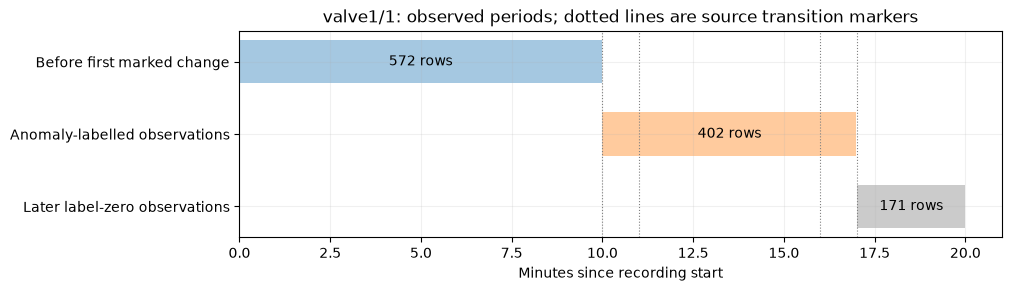

,first_observation,last_observation,rows
period,,,
Before first marked change,2020-03-09 10:34:33,2020-03-09 10:44:32,572
Anomaly-labelled observations,2020-03-09 10:44:33,2020-03-09 10:51:33,402
Later label-zero observations,2020-03-09 10:51:34,2020-03-09 10:54:33,171


The later label-zero period is excluded from the before/during comparisons.
One labelled experiment can contain several transition markers.


In [8]:
before_example = prefixes[example_id]
anomalous_example = example.loc[example_labels.anomaly.eq(1)]
later_zero = example.loc[example_labels.anomaly.eq(0)
                         & example.timestamp.gt(anomalous_example.timestamp.max())]
selected_periods = {
    "Before first marked change": before_example,
    "Anomaly-labelled observations": anomalous_example,
    "Later label-zero observations": later_zero,
}
period_rows = []
fig, ax = plt.subplots(figsize=(10, 2.8), layout="constrained")
for position, ((title, frame), colour) in enumerate(zip(
        selected_periods.items(), ("tab:blue", "tab:orange", "tab:grey"))):
    start = (frame.timestamp.min() - origin).total_seconds() / 60
    end = (frame.timestamp.max() - origin).total_seconds() / 60
    ax.barh(2 - position, end - start, left=start, height=.6, color=colour, alpha=.4)
    ax.text((start + end) / 2, 2 - position, f"{len(frame)} rows", ha="center", va="center")
    period_rows.append({"period": title, "first_observation": frame.timestamp.min(),
                        "last_observation": frame.timestamp.max(), "rows": len(frame)})
change_minutes = (example_labels.loc[example_labels.changepoint.eq(1), "timestamp"] - origin).dt.total_seconds() / 60
for minute in change_minutes:
    ax.axvline(minute, color="grey", linestyle=":", linewidth=.8)
ax.set(yticks=[2, 1, 0], yticklabels=list(selected_periods),
       xlabel="Minutes since recording start",
       title=f"{example_id}: observed periods; dotted lines are source transition markers")
plt.show()
period_selection = pd.DataFrame(period_rows).set_index("period")
display(period_selection)
print("The later label-zero period is excluded from the before/during comparisons.")
print("One labelled experiment can contain several transition markers.")

## 5. See all eight signals in one experiment
**Population: valve1/1 only, all recorded times.** The example was fixed in configuration, not selected
for the largest visible change. Its family describes restriction at the pump inlet; the plots do not
independently prove a causal mechanism.

Shading marks observed anomaly = 1 pieces; dashed lines mark supplied changepoints.
Lines break at flagged collection gaps. Neither shading nor markers are model predictions.

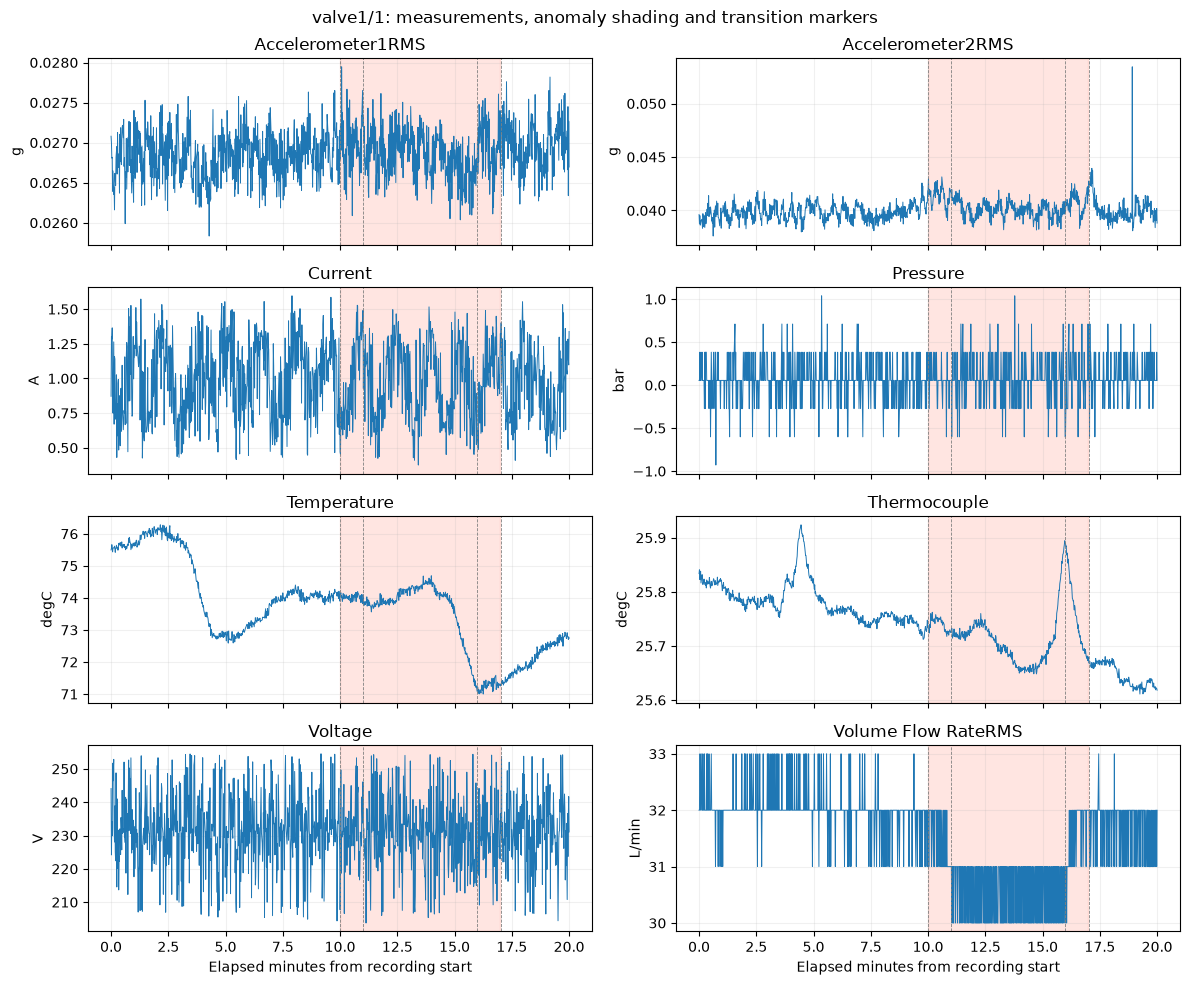

In [9]:
connected_groups = example.timestamp.diff().gt(pd.Timedelta(settings["gap_threshold"])).cumsum()
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
for ax, name in zip(axes.flat, names):
    for _, positions in example.groupby(connected_groups).groups.items():
        ax.plot(elapsed.loc[positions], example.loc[positions, name], linewidth=.7)
    for event in event_runs[example_id].itertuples():
        ax.axvspan((event.start - origin).total_seconds() / 60,
                   (event.last - origin).total_seconds() / 60, color="tomato", alpha=.16)
    for timestamp in example_labels.loc[example_labels.changepoint.eq(1), "timestamp"]:
        ax.axvline((timestamp - origin).total_seconds() / 60, color="grey", linestyle="--", linewidth=.6)
    ax.set(title=name, ylabel=units[name])
for ax in axes[-1]:
    ax.set_xlabel("Elapsed minutes from recording start")
fig.suptitle(f"{example_id}: measurements, anomaly shading and transition markers", fontsize=12)
fig.tight_layout()
plt.show()

**Observed in this example.** Flow moves from around 32 L/min toward 30–31 L/min during much
of the labelled interval, then rises again. Accelerometer2RMS changes more visibly than
Accelerometer1RMS. Current and voltage retain substantial short-term variation, while the motor
and fluid temperature traces also change outside the labelled interval.

The label applies to the experiment even when a particular channel shows little response.
This motivates both individual-signal and relationship checks; it does not justify treating every
sensor reading in the shaded interval as independently faulty.

## 6. Compare distributions within and across recordings
The first table describes **valve1/1 before its first marked change**. The second summarises
per-recording initial statistics across **all 26 development recordings**, excluding the separate normal
file. Each recording contributes one summary, regardless of its length.

The histograms compare the two periods identified in the timeline, within valve1/1 only. Each histogram
is normalised separately: height describes density, not the number of anomalies or their probability.
A median is a middle value; it does not describe the full distribution or the order of readings.

,min,median,max,sd,unique
measurement,,,,,
Accelerometer1RMS,0.02583,0.02684,0.02765,0.00030,561
Accelerometer2RMS,0.03761,0.03976,0.04257,0.00076,564
Current,0.41527,1.03695,1.59619,0.28184,571
Pressure,-0.92907,0.05471,1.03849,0.25151,7
Temperature,72.58970,74.08930,76.28010,1.14706,563
Thermocouple,25.71240,25.77455,25.92400,0.03763,445
Voltage,204.37200,231.42400,254.52000,10.95748,566
Volume Flow RateRMS,31.00000,32.00000,33.00000,0.43970,28


Between-recording summary — beginnings of 26 development recordings:


,smallest_recording_median,largest_recording_median,min_distinct_before_change,median_within_recording_sd
measurement,,,,
Accelerometer1RMS,0.02641,0.24843,103,0.00046
Accelerometer2RMS,0.03905,0.29108,103,0.00125
Current,0.92710,2.60062,104,0.27939
Pressure,0.05471,0.05471,5,0.25815
Temperature,67.21850,93.89940,104,0.42395
Thermocouple,22.07755,30.94865,86,0.02346
Voltage,227.18400,231.58500,104,10.77970
Volume Flow RateRMS,32.00000,128.00000,12,0.47391


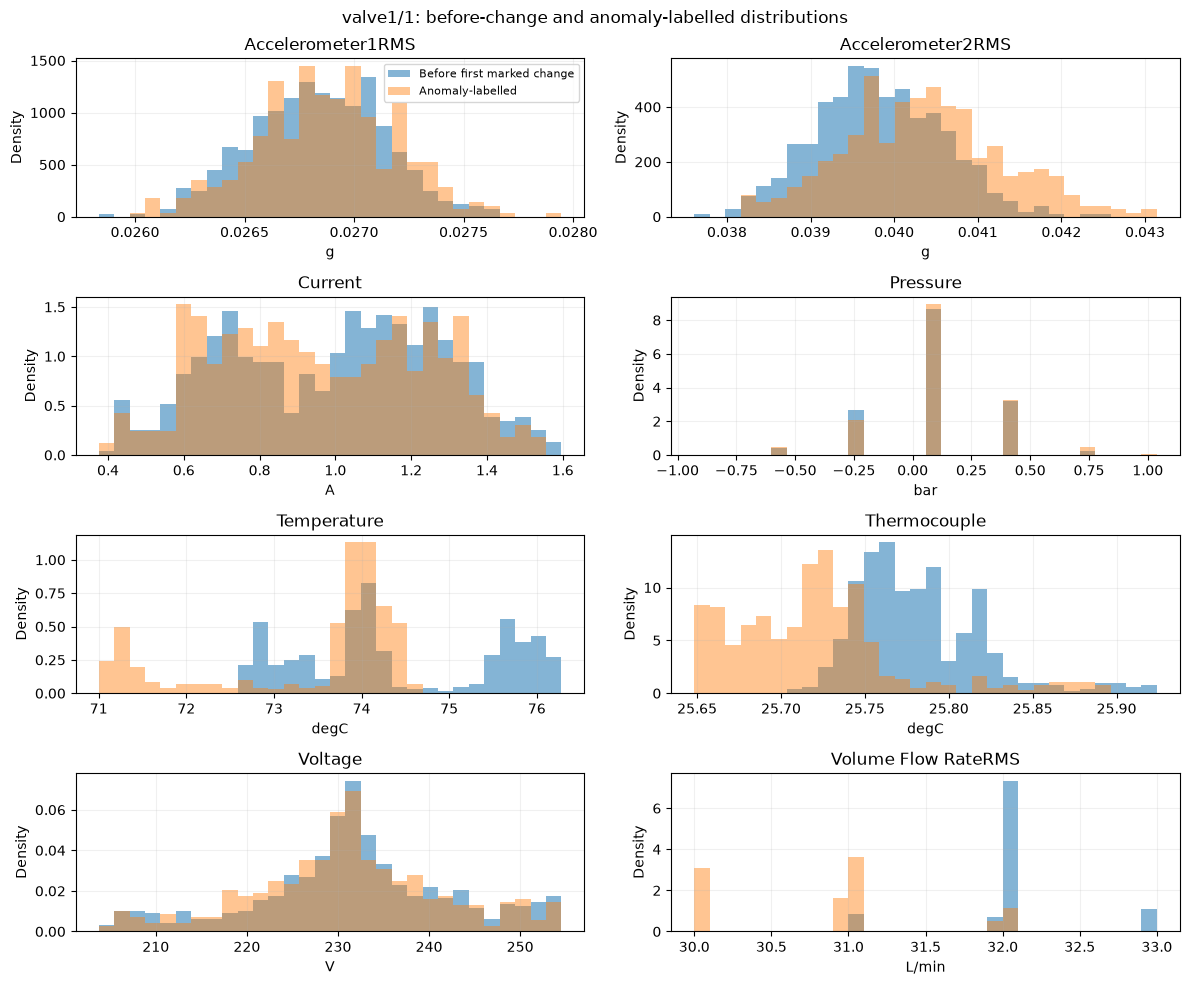

In [10]:
prefix_profiles = signal_profile(pd.concat(prefixes.values(), ignore_index=True), METRICS)
display(prefix_profiles.loc[prefix_profiles.entity_id.eq(example_id),
        ["measurement", "min", "median", "max", "sd", "unique"]].set_index("measurement").round(5))
development_profiles = prefix_profiles.loc[prefix_profiles.entity_id.isin(development_ids)]
baseline_spread = development_profiles.groupby("measurement").agg(
    smallest_recording_median=("median", "min"),
    largest_recording_median=("median", "max"),
    min_distinct_before_change=("unique", "min"),
    median_within_recording_sd=("sd", "median"))
print("Between-recording summary — beginnings of 26 development recordings:")
display(baseline_spread.round(5))

fig, axes = plt.subplots(4, 2, figsize=(12, 10))

for ax, name in zip(axes.flat, names):
    first = prefixes[example_id][name].dropna()
    second = anomalous_example[name].dropna()
    bins = np.histogram_bin_edges(np.r_[first, second], bins=30)
    ax.hist(first, bins=bins, density=True, alpha=.55, label="Before first marked change")
    ax.hist(second, bins=bins, density=True, alpha=.45, label="Anomaly-labelled")
    ax.set(title=name, xlabel=units[name], ylabel="Density")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"{example_id}: before-change and anomaly-labelled distributions")
fig.tight_layout()
plt.show()

A distribution difference describes an observed response, not detector accuracy. A pooled mean and
standard deviation may be particularly unhelpful for coarse or multimodal measurements. Also, a
recording-level label does not establish which individual signal values are abnormal.

## 7. Is the separate anomaly-free recording representative?
**Each dot is one recording's median before its first marked change.** Vertical bars show the middle
50% of its observed readings (25th–75th percentiles). They describe spread, not confidence intervals.
The dashed line is the median across the **whole separate anomaly-free file**, not an alarm threshold.

Colours identify intended experiment families, not health or observed operating states. The horizontal
axis is ordered by family and numeric filename; **it is not time**. Each sensor has its own vertical
scale and unit, so apparent distances cannot be compared directly between panels.

The support table gives the unequal observation counts behind the dots and reference line.

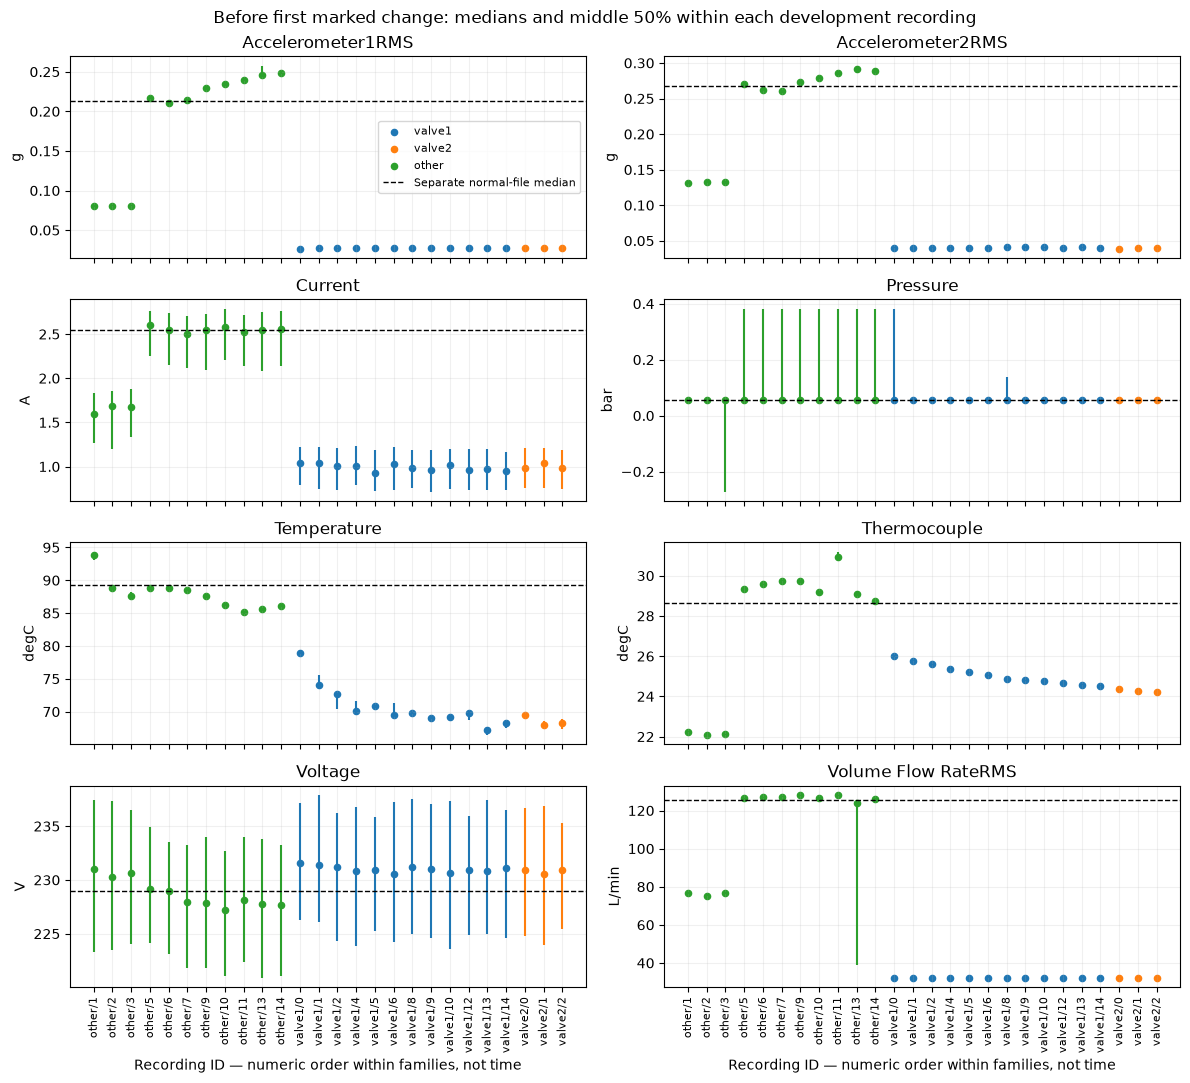

,population,observed_rows,first_to_last_span_s
recording_id,,,
anomaly-free/anomaly-free,whole separate normal file,9405,9960.0
other/1,before first marked change,557,583.0
other/2,before first marked change,104,107.0
other/3,before first marked change,568,598.0
other/5,before first marked change,572,599.0
other/6,before first marked change,573,599.0
other/7,before first marked change,572,599.0
other/9,before first marked change,572,598.0
other/10,before first marked change,570,599.0


Separate normal flow median: 125.677 L/min.
Development initial flow medians: 32.000–128.000 L/min.


In [11]:
reference_medians = recordings[reference_id][names].median()
initial_medians = pd.DataFrame({key: prefixes[key][names].median() for key in development_ids}).T
family_colours = {"valve1": "tab:blue", "valve2": "tab:orange", "other": "tab:green"}
fig, axes = plt.subplots(4, 2, figsize=(12, 11), sharex=True)
for ax, name in zip(axes.flat, names):
    profile = development_profiles.loc[development_profiles.measurement.eq(name)].set_index("entity_id")
    profile = profile.reindex(development_ids)
    for family, colour in family_colours.items():
        positions = [i for i, key in enumerate(development_ids) if key.startswith(family + "/")]
        group = profile.iloc[positions]
        ax.vlines(positions, group.q25, group.q75, color=colour, linewidth=1.5)
        ax.scatter(positions, group["median"], s=20, color=colour, label=family)
    ax.axhline(reference_medians[name], color="black", linestyle="--", linewidth=1,
               label="Separate normal-file median")
    ax.set(title=name, ylabel=units[name])
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xticks(range(len(development_ids)))
    ax.set_xticklabels(development_ids, rotation=90, fontsize=8)
    ax.set_xlabel("Recording ID — numeric order within families, not time")
fig.suptitle("Before first marked change: medians and middle 50% within each development recording")
fig.tight_layout()
plt.show()
support_rows = []
for identifier, frame in prefixes.items():
    support_rows.append({
        "recording_id": identifier,
        "population": "whole separate normal file" if identifier == reference_id else "before first marked change",
        "observed_rows": len(frame),
        "first_to_last_span_s": (frame.timestamp.max() - frame.timestamp.min()).total_seconds(),
    })
reference_support = pd.DataFrame(support_rows).set_index("recording_id")
display(reference_support.round(1))
print(f"Separate normal flow median: {reference_medians['Volume Flow RateRMS']:.3f} L/min.")
print(f"Development initial flow medians: {initial_medians['Volume Flow RateRMS'].min():.3f}–"
      f"{initial_medians['Volume Flow RateRMS'].max():.3f} L/min.")

**Observed:** starting flow, vibration, current and temperature differ between recordings. Using the
separate normal file as an unquestioned target could flag an experiment before its marked intervention.
The plot does not establish why these levels differ or prove that the beginnings are faulty.

Pressure medians coincide, but its readings vary: equal medians do not imply identical distributions or
a constant sensor. Bars can also collapse when many recorded values are tied. Even the middle 50% hides
tails and temporal changes. No independent-sample confidence intervals are claimed.

Notebook 02 should compare reference choices and transfer explicitly. This figure does not determine
the number of operating regimes or require a separate model for every recording. Family names and
recording IDs are not proposed sensor predictors.

## 8. Does recent history matter?
**First population: before the first marked change in valve1/1.** Autocorrelation (ACF) compares one
sensor with itself at earlier times. A lag of five seconds compares neighbouring five-second averages.

| ACF | Interpretation at that lag |
| --- | --- |
| Positive | Above-average readings tend to accompany above-average earlier readings |
| Near zero | Little linear association; not proof of independence or uselessness |
| Negative | Above-average readings tend to accompany below-average earlier readings |

Every nonconstant series has ACF = 1 at lag zero. ACF is not an anomaly probability or a measure of
health. A slow trend can create high ACF even without a stable forecasting relationship.

**Sampling comes first.** The longest exactly one-second segment is short because a two-second spacing
breaks it. That does not discard all other readings. For a longer view, we return to the **whole initial
portion** and average non-overlapping five-second windows with at least four finite observations.

```text
[10:34:35, 10:34:40) → average of available readings → available at 10:34:40
[10:34:40, 10:34:45) → next average                  → available at 10:34:45
```

Unsupported windows stay missing. The table's timestamps are right endpoints (availability times).
`contiguous_5s_bins` is the segment used for ACF; `all_supported_5s_bins` counts every supported window.
They happen to agree here. Aggregation smooths fast events and changes the signal; it is not a decision
to use five-second data in the future model.

The [statsmodels ACF](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.stattools.acf.html)
uses demeaned covariance on the longest supported regular segment. We inspect at most one quarter of
that segment in lags, capped at 120 seconds. This is a diagnostic choice, without IID significance bands.

Longest exactly one-second segment before the first mark: {'start': Timestamp('2020-03-09 10:34:40'), 'end': Timestamp('2020-03-09 10:35:03'), 'samples': 24}
Those 24 observations span 23 elapsed seconds; the full initial portion contains 572 observations.


,first_bin_available_at,last_bin_available_at,contiguous_5s_bins,all_supported_5s_bins,acf_5seconds
measurement,,,,,
Accelerometer1RMS,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.454
Accelerometer2RMS,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.479
Current,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.657
Pressure,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,-0.060
Temperature,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.992
Thermocouple,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.961
Voltage,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,-0.005
Volume Flow RateRMS,2020-03-09 10:34:40,2020-03-09 10:44:30,119,119,0.491


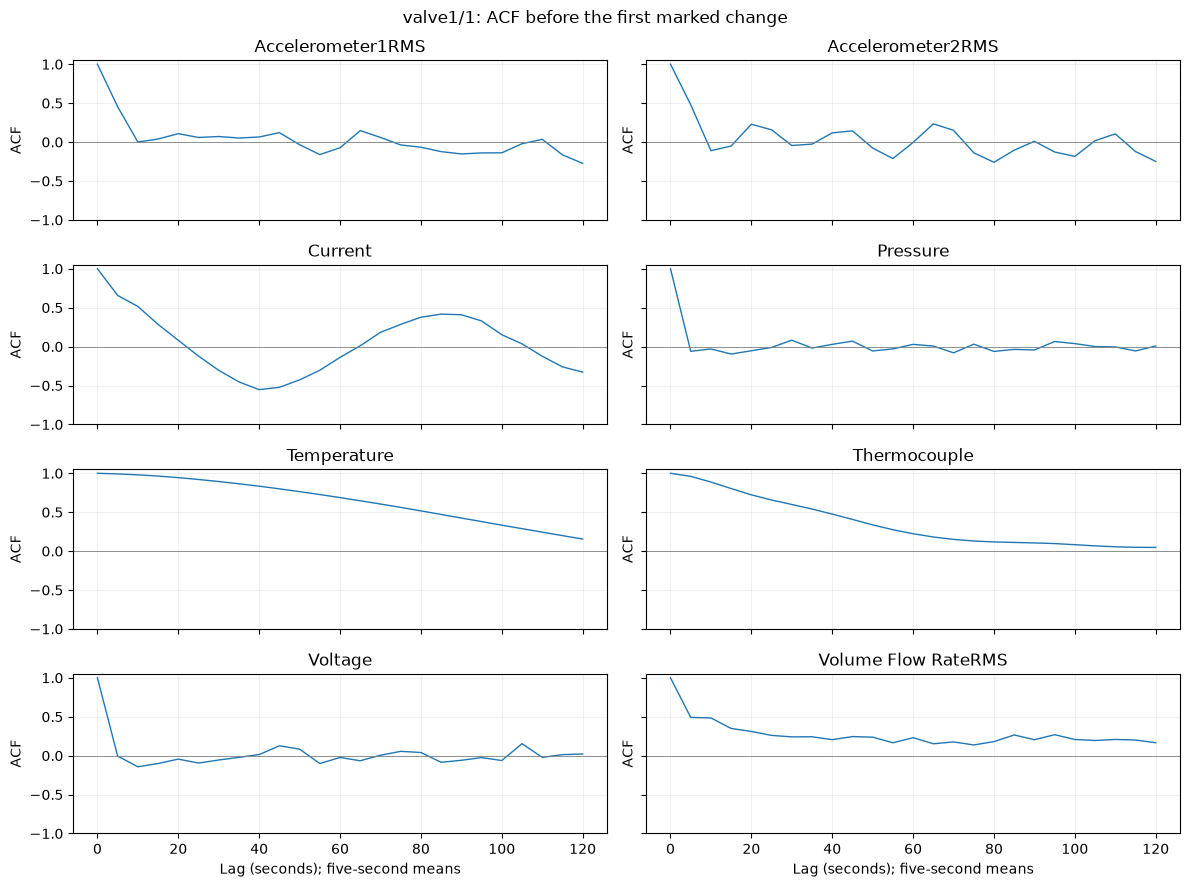

In [12]:
native_acf, native_info = segment_acf(
    prefixes[example_id].set_index("timestamp")["Temperature"], "1s", 60)
print("Longest exactly one-second segment before the first mark:", native_info)
print(f"Those {native_info['samples']} observations span "
      f"{(native_info['end'] - native_info['start']).total_seconds():.0f} elapsed seconds; "
      f"the full initial portion contains {len(before_example)} observations.")
five_second, support = aggregate_gauges(prefixes[example_id], names, "5s", 4)
five_second.index += pd.Timedelta(seconds=5)  # Completed-bin availability.
acf_rows = []
curves = {}
for name in names:
    curves[name], info = segment_acf(five_second[name], "5s", 24)
    acf_rows.append({"measurement": name, **info,
                     "usable_bins": int(five_second[name].notna().sum()),
                     "acf_5seconds": curves[name].acf.iloc[1] if len(curves[name]) > 1 else np.nan})
acf_summary = pd.DataFrame(acf_rows)
display(acf_summary.rename(columns={
    "start": "first_bin_available_at", "end": "last_bin_available_at",
    "samples": "contiguous_5s_bins", "usable_bins": "all_supported_5s_bins",
}).set_index("measurement").round(3))

fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, name in zip(axes.flat, names):
    curve = curves[name]
    ax.plot(curve.lag_steps * 5, curve.acf, linewidth=1)
    ax.axhline(0, color="grey", linewidth=.6)
    ax.set(title=name, ylabel="ACF", ylim=(-1, 1.05))
for ax in axes[-1]:
    ax.set_xlabel("Lag (seconds); five-second means")
fig.suptitle(f"{example_id}: ACF before the first marked change")
fig.tight_layout()
plt.show()

### Does the minimum number of observations change the evidence?
**Population: the same valve1/1 portion, two thermal signals.** The next table changes only the required
observations per five-second window. This is a support check, not optimisation of an anomaly detector.
NaN means the segment is too short or constant to report the chosen ACF, not “no dependence”.

In [13]:
sensitivity_rows = []
for minimum in (3, 4, 5):
    aggregate, counts = aggregate_gauges(prefixes[example_id], names, "5s", minimum)
    for name in ("Temperature", "Thermocouple"):
        curve, info = segment_acf(aggregate[name], "5s", 24)
        sensitivity_rows.append({"minimum_samples": minimum, "measurement": name,
                                 "all_supported_5s_bins": int(aggregate[name].notna().sum()),
                                 "contiguous_5s_bins": info["samples"],
                                 "acf_5seconds": curve.acf.iloc[1] if len(curve) > 1 else np.nan})
display(pd.DataFrame(sensitivity_rows).round(3))

,minimum_samples,measurement,all_supported_5s_bins,contiguous_5s_bins,acf_5seconds
0,3,Temperature,120,120,0.992
1,3,Thermocouple,120,120,0.963
2,4,Temperature,119,119,0.992
3,4,Thermocouple,119,119,0.961
4,5,Temperature,91,4,NaN
5,5,Thermocouple,91,4,NaN


**Observed:** the example's five-second temperature ACF decays slowly, while pressure and voltage
have little lag-one dependence at that resolution. Current shows an oscillating ACF. These findings
describe one short initial portion and require checks across other recordings before choosing a model.

Strong ACF can arise from drift as well as predictable fluctuations; it does not establish seasonality
or stationarity. The three- and four-sample support rules give similar thermal ACFs here. Requiring
five observations leaves very short uninterrupted segments, so the reported ACF is undefined.
That loss of evidence is preferable to silently filling gaps.

These short experiments cannot substantiate daily or weekly seasonality. Repetition within a trace
may reflect equipment dynamics, but requires stable repeated cycles and validation in other recordings.
No seasonal decomposition is justified here.

### Do these temporal patterns extend beyond the example?
**Population: beginnings of all 26 development recordings; the separate normal file is excluded.**
We repeat the same five-second support and segment-selection rules for each recording and measurement.

We also remove a fitted straight-line trend **within that same selected segment**, then recalculate ACF.
This is a retrospective sensitivity check, not a forecasting fit or proposed preprocessing rule.
It helps ask whether a simple drift explains the persistence; nonlinear trends can remain.
The raw and adjusted calculations use identical timestamps. Exactly linear series have no remaining
variation, so their adjusted ACF is undefined.

Each recording contributes one ACF estimate. Short segments and temporal dependence make this a
descriptive comparison, not a statistical significance test or proof of stationarity.

,recordings_with_raw_acf,recordings_with_adjusted_acf,min_segment_bins,median_segment_bins,min_raw_acf_5s,median_raw_acf_5s,max_raw_acf_5s,median_detrended_acf_5s
measurement,,,,,,,,
Accelerometer1RMS,26,26,22,119.5,-0.208,0.499,0.961,0.434
Accelerometer2RMS,26,26,22,119.5,0.068,0.624,0.884,0.574
Current,26,26,22,119.5,0.045,0.662,0.754,0.650
Pressure,26,26,22,119.5,-0.142,0.002,0.171,-0.018
Temperature,26,26,22,119.5,0.783,0.953,0.993,0.909
Thermocouple,26,26,22,119.5,0.521,0.954,0.984,0.940
Voltage,26,26,22,119.5,-0.095,0.039,0.204,0.023
Volume Flow RateRMS,26,26,22,119.5,-0.144,0.445,0.909,0.300


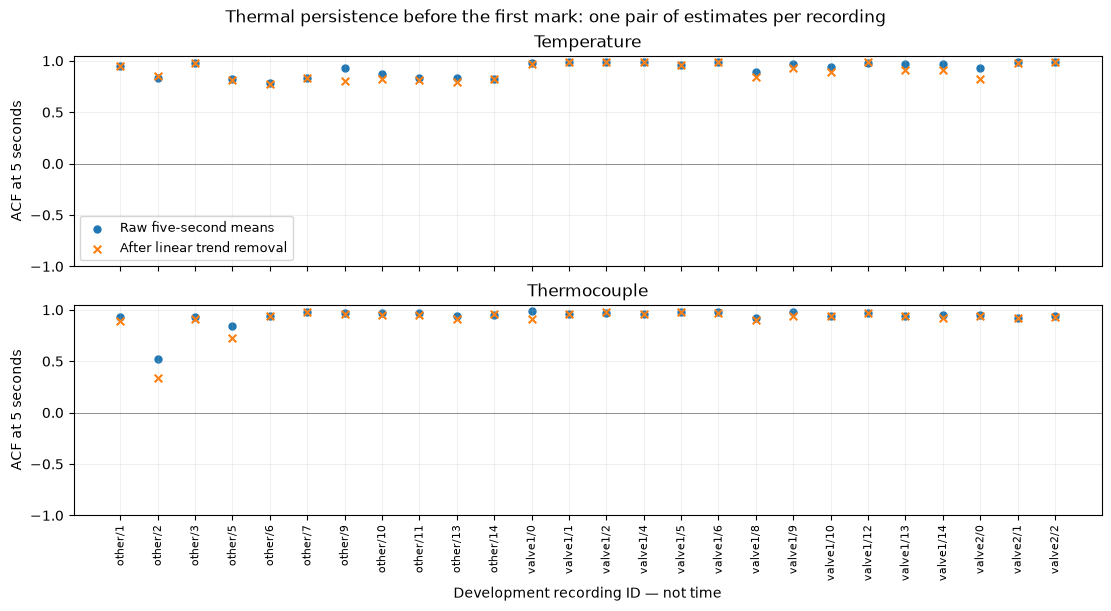

Temperature: median ACF 0.953 before and 0.909 after removing a straight-line trend.
Thermocouple: median ACF 0.954 before and 0.940 after removing a straight-line trend.


In [14]:
temporal_rows = []
for identifier in development_ids:
    means, _ = aggregate_gauges(prefixes[identifier], names, "5s", 4)
    means.index += pd.Timedelta(seconds=5)
    for name in names:
        raw_curve, info = segment_acf(means[name], "5s", 24)
        adjusted_curve, adjusted_info = segment_acf(means[name], "5s", 24, remove_linear_trend=True)
        assert info == adjusted_info
        temporal_rows.append({
            "recording_id": identifier, "measurement": name,
            "first_bin_available_at": info["start"], "last_bin_available_at": info["end"],
            "contiguous_5s_bins": info["samples"],
            "all_supported_5s_bins": int(means[name].notna().sum()),
            "raw_acf_5s": raw_curve.acf.iloc[1] if len(raw_curve) > 1 else np.nan,
            "detrended_acf_5s": adjusted_curve.acf.iloc[1] if len(adjusted_curve) > 1 else np.nan,
        })
temporal_comparison = pd.DataFrame(temporal_rows)
temporal_summary = temporal_comparison.groupby("measurement").agg(
    recordings_with_raw_acf=("raw_acf_5s", "count"),
    recordings_with_adjusted_acf=("detrended_acf_5s", "count"),
    min_segment_bins=("contiguous_5s_bins", "min"),
    median_segment_bins=("contiguous_5s_bins", "median"),
    min_raw_acf_5s=("raw_acf_5s", "min"),
    median_raw_acf_5s=("raw_acf_5s", "median"),
    max_raw_acf_5s=("raw_acf_5s", "max"),
    median_detrended_acf_5s=("detrended_acf_5s", "median"),
)
display(temporal_summary.round(3))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes, ("Temperature", "Thermocouple")):
    rows = temporal_comparison.loc[temporal_comparison.measurement.eq(name)].set_index("recording_id")
    rows = rows.reindex(development_ids)
    ax.scatter(range(len(rows)), rows.raw_acf_5s, s=25, label="Raw five-second means")
    ax.scatter(range(len(rows)), rows.detrended_acf_5s, s=30, marker="x", label="After linear trend removal")
    ax.axhline(0, color="grey", linewidth=.6)
    ax.set(title=name, ylabel="ACF at 5 seconds", ylim=(-1, 1.05))
axes[0].legend(fontsize=9)
axes[-1].set_xticks(range(len(development_ids)), development_ids, rotation=90, fontsize=8)
axes[-1].set_xlabel("Development recording ID — not time")
fig.suptitle("Thermal persistence before the first mark: one pair of estimates per recording")
plt.show()
for name in ("Temperature", "Thermocouple"):
    row = temporal_summary.loc[name]
    print(f"{name}: median ACF {row.median_raw_acf_5s:.3f} before and "
          f"{row.median_detrended_acf_5s:.3f} after removing a straight-line trend.")

**Observed across the 26 development recordings:** the median five-second ACF falls from 0.953 to
0.909 for motor temperature and from 0.954 to 0.940 for fluid temperature after straight-line trend
removal. Persistence remains strong in many recordings, so a simple linear drift does not fully explain
it. This supports testing limited recent-history baselines later; it does not establish their accuracy.

The paired markers also show variation between recordings. A small change does not rule out nonlinear
drift; a large change does not make the trend irrelevant to anomaly detection. Keep level changes visible
when evaluating future history-based models.

The shortest selected segment has only 22 five-second bins, so not all estimates carry equal evidence.
No automatic model choice or significance threshold follows from this table. Short experiments cannot
establish daily/weekly seasonality or long-term stationarity.

## 9. Do relationships between sensors change?
**Both heatmaps concern valve1/1.** The left uses the beginning before the first marked change;
the right uses rows where the supplied anomaly label equals one. Later label-zero observations shown
in the earlier timeline are excluded from both. The titles state the observed endpoints and row counts.

Each cell compares **two sensors measured at the same times** using Spearman rank correlation.
Red means higher values tend to occur together, blue means higher values in one tend to accompany
lower values in the other, and near-neutral means weak rank association. The diagonal is always one
for nonconstant sensors. These colours do not encode health, unlike the annotation shading.

Different row counts, ties, drift and dependence limit interpretation. Changed correlation is not
automatically evidence of a causal relationship, separate faulty sensors or detector performance.

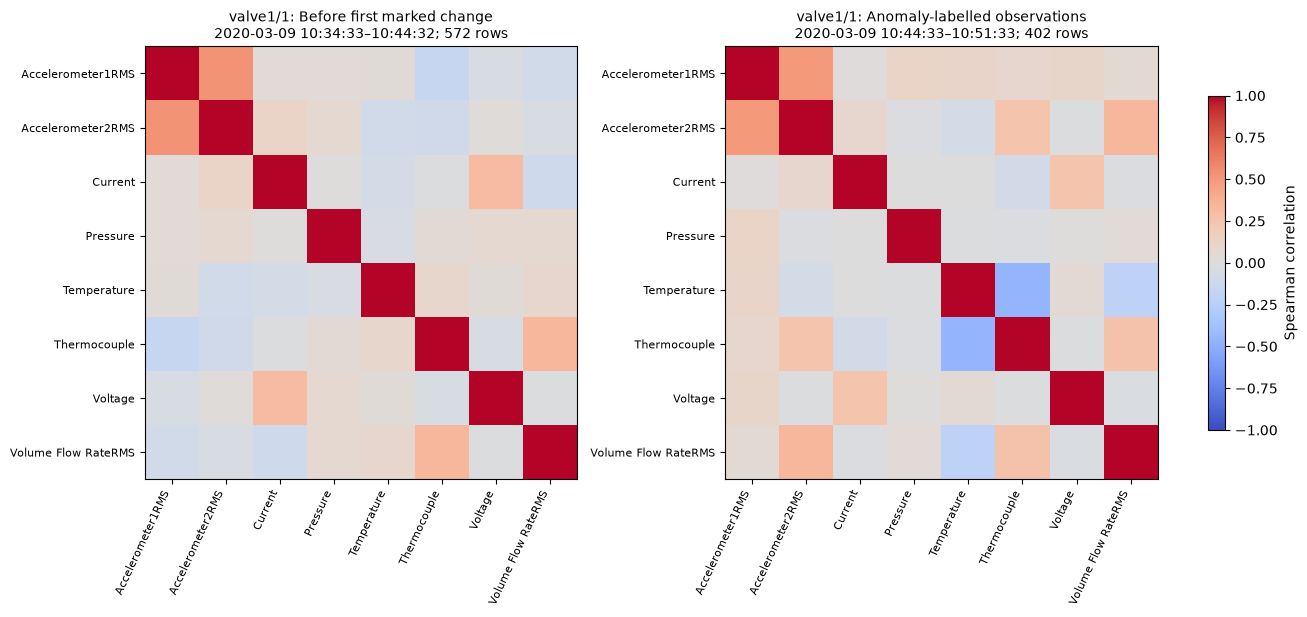

Recorded timestamps have unknown timezone. Endpoints are first and last included observations.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
for ax, frame, title in zip(axes, (before_example, anomalous_example),
                           ("Before first marked change", "Anomaly-labelled observations")):
    correlation = frame[names].corr(method="spearman")
    picture = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(names)), names, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    first, last = frame.timestamp.min(), frame.timestamp.max()
    ax.set_title(f"{example_id}: {title}\n{first:%Y-%m-%d %H:%M:%S}–{last:%H:%M:%S}; {len(frame)} rows",
                 fontsize=10)
    ax.grid(False)
fig.colorbar(picture, ax=axes, shrink=.7, label="Spearman correlation")
plt.show()
print("Recorded timestamps have unknown timezone. Endpoints are first and last included observations.")

**Additional scope: four selected sensor pairs, calculated separately for each initial portion.**
The next summary uses the 26 development recordings, with the separate normal file displayed on its
own. It avoids pooling different operating levels into an apparently stronger correlation.
Minimum and maximum values describe variation between recordings, not confidence limits.

In [16]:
pairs = [("Accelerometer1RMS", "Accelerometer2RMS"), ("Current", "Voltage"),
         ("Pressure", "Volume Flow RateRMS"), ("Temperature", "Thermocouple")]
relationships = []
for identifier, frame in prefixes.items():
    result = relationship_report(frame, pairs)
    result["recording_id"] = identifier
    relationships.append(result)
relationships = pd.concat(relationships, ignore_index=True)
development_relationships = relationships.loc[relationships.recording_id.isin(development_ids)]
relationship_summary = development_relationships.groupby(["first", "second"]).agg(
    valid_recordings=("spearman", "count"),
    min_spearman=("spearman", "min"), median_spearman=("spearman", "median"),
    max_spearman=("spearman", "max"))
print("Selected pairs — beginnings of the 26 development recordings:")
display(relationship_summary.round(3))
print("Same pairs — whole separate normal recording:")
display(relationships.loc[relationships.recording_id.eq(reference_id),
                          ["first", "second", "pairs", "spearman"]].set_index(["first", "second"]).round(3))

Selected pairs — beginnings of the 26 development recordings:


,,valid_recordings,min_spearman,median_spearman,max_spearman
first,second,,,,
Accelerometer1RMS,Accelerometer2RMS,26,-0.741,0.506,0.821
Current,Voltage,26,0.254,0.329,0.505
Pressure,Volume Flow RateRMS,26,-0.096,-0.021,0.058
Temperature,Thermocouple,26,-0.774,-0.086,0.628


Same pairs — whole separate normal recording:


,,pairs,spearman
first,second,,
Accelerometer1RMS,Accelerometer2RMS,9405,-0.300
Current,Voltage,9405,0.419
Pressure,Volume Flow RateRMS,9405,-0.000
Temperature,Thermocouple,9405,-0.834


**Interpretation.** Relationships that differ across recordings are candidates for conditional
monitoring, not universal equations. Shared trends or a common intervention can also create
correlation. A multivariate detector will need a stated fitting population and must be compared
against individual-signal baselines; this notebook does not establish that it will be better.

## 10. What should Notebook 02 investigate?
Keep all eight measurements as candidates. We have clarified what can be compared without assuming
that the separate normal file is representative, that an initial portion is verified healthy, or that
one example describes the whole dataset.

The handover combines **development-only recording summaries** with the temporal comparison across
those recordings. It does not merge different experiments into one time series. No feature is removed
solely for weak correlation, and no automatic model selection is introduced.

In [17]:
cautions = {
    "Accelerometer1RMS": "Monitor amplitude; do not infer a vibration spectrum from RMS.",
    "Accelerometer2RMS": "Compare both vibration channels; assess cross-recording shifts.",
    "Current": "Preserve noisy native variation; compare with electrical context.",
    "Pressure": "Coarse levels and negative values; verify meaning before physical limits.",
    "Temperature": "Strong persistence may include drift; consider limited causal history.",
    "Thermocouple": "Separate fluid from motor temperature; check drift and regime transfer.",
    "Voltage": "Retain as a measurement; do not assume a fixed supply distribution.",
    "Volume Flow RateRMS": "Large reference-level differences; do not pool operating regimes.",
}
handover = baseline_spread.join(temporal_summary[["median_raw_acf_5s", "median_detrended_acf_5s"]])
handover["unit"] = pd.Series(units)
handover["next_step"] = pd.Series(cautions)
display(handover[["unit", "smallest_recording_median", "largest_recording_median",
                  "min_distinct_before_change", "median_raw_acf_5s", "median_detrended_acf_5s", "next_step"]].round(4))
print("ACF entries are medians across development recordings, not a pooled-series ACF.")
for filename, table in {
    "recording_quality.csv": timing_view, "signal_profiles.csv": profiles,
    "label_audit.csv": label_audit, "annotation_boundaries.csv": boundary_audit,
    "reference_support.csv": reference_support, "temporal_comparison.csv": temporal_comparison, "initial_prefix_profiles.csv": prefix_profiles,
    "relationship_summary.csv": relationship_summary, "handover.csv": handover,
}.items():
    table.rename(columns={"entity_id": "recording_id"}).to_csv(OUTPUT / filename, index=True)
versions = {package: version(package) for package in ("numpy", "pandas", "matplotlib", "statsmodels", "nbclient")}
run_manifest = {
    "source_commit": settings["source_commit"],
    "opened_recordings": list(recordings),
    "reserved_recordings": sorted(reserved),
    "source_files": settings["files"],
    "python": platform.python_version(), "packages": versions,
     "gap_threshold": settings["gap_threshold"], "acf_frequency": "5s", "acf_minimum_samples": 4,
    "acf_trend_sensitivity": "least-squares straight line within each selected segment",
    "temporal_comparison_recordings": development_ids,
    "review_notes_applied": [1, 2, 3, 4, 5, 6, 7],
}
(OUTPUT / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
assert set(run_manifest["opened_recordings"]).isdisjoint(run_manifest["reserved_recordings"])
print("Saved small diagnostic tables and provenance under outputs/skab_assessment (Git-ignored).")
print("Environment:", versions)

,unit,smallest_recording_median,largest_recording_median,min_distinct_before_change,median_raw_acf_5s,median_detrended_acf_5s,next_step
measurement,,,,,,,
Accelerometer1RMS,g,0.0264,0.2484,103,0.4992,0.4336,Monitor amplitude; do not infer a vibration spectrum from RMS.
Accelerometer2RMS,g,0.0390,0.2911,103,0.6236,0.5735,Compare both vibration channels; assess cross-recording shifts.
Current,A,0.9271,2.6006,104,0.6619,0.6499,Preserve noisy native variation; compare with electrical context.
Pressure,bar,0.0547,0.0547,5,0.0017,-0.0176,Coarse levels and negative values; verify meaning before physical limits.
Temperature,degC,67.2185,93.8994,104,0.9533,0.9086,Strong persistence may include drift; consider limited causal history.
Thermocouple,degC,22.0776,30.9486,86,0.9539,0.9397,Separate fluid from motor temperature; check drift and regime transfer.
Voltage,V,227.1840,231.5850,104,0.0390,0.0234,Retain as a measurement; do not assume a fixed supply distribution.
Volume Flow RateRMS,L/min,32.0000,128.0000,12,0.4454,0.3002,Large reference-level differences; do not pool operating regimes.


ACF entries are medians across development recordings, not a pooled-series ACF.
Saved small diagnostic tables and provenance under outputs/skab_assessment (Git-ignored).
Environment: {'numpy': '2.3.5', 'pandas': '2.3.3', 'matplotlib': '3.11.2', 'statsmodels': '0.14.6', 'nbclient': '0.11.0'}


**Decisions carried forward**

- Preserve the original source distinction (34 labelled experiments plus one normal file) and our
  separate usage decision (26 development, one reference, eight unopened test recordings).
- Keep recording boundaries, gaps and annotations explicit. A gap is not proof of downtime; a positive
  piece or changepoint is not automatically a separate physical incident. Treat uncertain boundaries
  carefully when assessing future detection delay.
- Compare reference choices using development data. Any calibration on a new recording needs a
  predeclared, chronological policy independent of future labels. The initial portions used here were
  chosen retrospectively and do not supply that policy.
- Evaluate simple individual-signal references first; inspect temporal residuals before adding
  multivariate comparisons. Lower prediction error alone may conceal a developing level shift.
- Keep the fixed test reservation. Family colours, recording IDs and supplied annotations are not
  proposed sensor predictors.

**Limits.** One controlled testbed and short experiments do not establish cross-industry performance,
seasonal behaviour or field false-alarm rates. The added summaries reveal variability but do not provide
independent-sample uncertainty estimates. Passing data-quality checks is not proof of realism.

**Sources.** Dataset meanings and intended interventions come from the pinned SKAB documentation linked
at the beginning. Citation: Katser & Kozitsin (2020),
[Skoltech Anomaly Benchmark](https://doi.org/10.34740/KAGGLE/DSV/1693952).
The ACF implementation is documented in the statsmodels link in Section 8.
Partitions, support rules, trend sensitivity and interpretations are our explicit analytical choices.